# German Credit Risk: EDA, Baseline Classification, and Borrower Segmentation

**Dataset:** [UCI Statlog (German Credit Data)](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data)
— 1000 loan applicants from a German bank, 20 attributes, contributed by
Prof. Dr. Hans Hofmann (Universitat Hamburg), hosted by the UCI Machine
Learning Repository. Downloaded directly from
`archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data`
on 2026-07-31.

**Task:** predict whether an applicant is a good (0) or bad (1) credit risk,
and separately, segment borrowers with K-Means clustering.

**Approach:** full EDA -> documented preprocessing -> baseline Logistic
Regression / Decision Tree / Random Forest -> honest metric comparison
(including the dataset's published cost matrix) -> unsupervised borrower
segmentation -> SQL queries against a local SQLite copy of the data.

All numbers in this notebook are computed live, not hand-typed.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 25)

from data_loader import load_labeled
from preprocessing import build_preprocessor, get_train_test_split, NUMERIC_COLS, CATEGORICAL_COLS


## 1. Load Data

In [2]:
df = load_labeled()
print("Shape:", df.shape)
df.head()


Shape: (1000, 21)


,checking_account_status,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate_pct,personal_status_sex,other_debtors_guarantors,present_residence_since,property,age_years,other_installment_plans,housing,existing_credits_count,job,num_dependents,telephone,foreign_worker,target
0,< 0 DM,6,critical account / other credits elsewhere,radio/television,1169,unknown / no savings account,>= 7 years,4,male: single,none,4,real estate,67,none,own,2,skilled employee/official,1,"yes, registered",yes,0
1,0-200 DM,48,existing credits paid duly till now,radio/television,5951,< 100 DM,1-4 years,2,female: divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee/official,1,none,yes,1
2,no checking account,12,critical account / other credits elsewhere,education,2096,< 100 DM,4-7 years,2,male: single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,< 0 DM,42,existing credits paid duly till now,furniture/equipment,7882,< 100 DM,4-7 years,2,male: single,guarantor,4,building society savings / life insurance,45,none,for free,1,skilled employee/official,2,none,yes,0
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1-4 years,3,male: single,none,4,unknown / no property,53,none,for free,2,skilled employee/official,2,none,yes,1


## 2. Exploratory Data Analysis

### 2.1 Structure & missing values

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   checking_account_status   1000 non-null   object
 1   duration_months           1000 non-null   int64 
 2   credit_history            1000 non-null   object
 3   purpose                   1000 non-null   object
 4   credit_amount             1000 non-null   int64 
 5   savings_account           1000 non-null   object
 6   employment_since          1000 non-null   object
 7   installment_rate_pct      1000 non-null   int64 
 8   personal_status_sex       1000 non-null   object
 9   other_debtors_guarantors  1000 non-null   object
 10  present_residence_since   1000 non-null   int64 
 11  property                  1000 non-null   object
 12  age_years                 1000 non-null   int64 
 13  other_installment_plans   1000 non-null   object
 14  housing                  

In [4]:
missing = df.isnull().sum()
print("Total missing cells:", missing.sum(), "out of", df.size)
missing[missing > 0]


Total missing cells: 0 out of 21000


Series([], dtype: int64)

No missing values. This dataset was pre-cleaned by StatLog for benchmark use —
a real production pull from a bank's core system would almost certainly have
missing income fields, inconsistent categorical codes, or duplicate applicants.
That gap is a real limitation of this project's realism, noted here rather than
glossed over.

### 2.2 Class balance

target
0    700
1    300
Name: count, dtype: int64
target
0    70.0
1    30.0
Name: proportion, dtype: float64


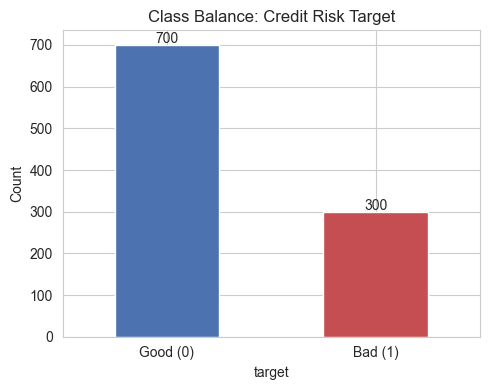

In [5]:
counts = df["target"].value_counts()
pct = df["target"].value_counts(normalize=True) * 100
print(counts)
print(pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
counts.sort_index().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Good (0)", "Bad (1)"], rotation=0)
ax.set_title("Class Balance: Credit Risk Target")
ax.set_ylabel("Count")
for i, v in enumerate(counts.sort_index()):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()


**70/30 imbalance.** A model predicting "good" for every applicant already
scores 70% accuracy while catching zero defaulters -- this is the floor every
model below is judged against, not 0%.

### 2.3 Numeric distributions

In [6]:
NUMERIC_COLS_ = NUMERIC_COLS
df[NUMERIC_COLS_].describe().T


,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate_pct,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
present_residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age_years,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits_count,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


### 2.4 Credit amount distribution by risk class

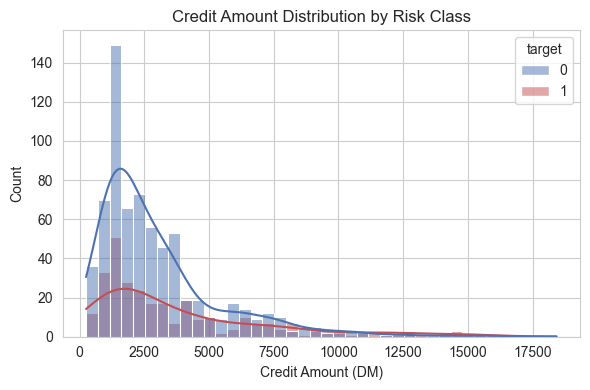

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df, x="credit_amount", hue="target", bins=40, kde=True,
             palette={0: "#4C72B0", 1: "#C44E52"}, ax=ax)
ax.set_title("Credit Amount Distribution by Risk Class")
ax.set_xlabel("Credit Amount (DM)")
plt.tight_layout()
plt.show()


### 2.5 Age distribution by risk class

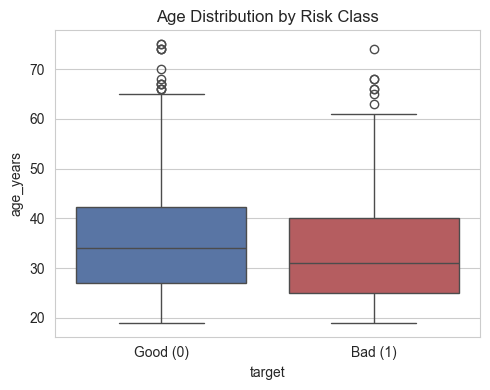

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df, x="target", y="age_years", hue="target",
            palette={0: "#4C72B0", 1: "#C44E52"}, legend=False, ax=ax)
ax.set_xticklabels(["Good (0)", "Bad (1)"])
ax.set_title("Age Distribution by Risk Class")
plt.tight_layout()
plt.show()


### 2.6 Correlation matrix (numeric features + target)

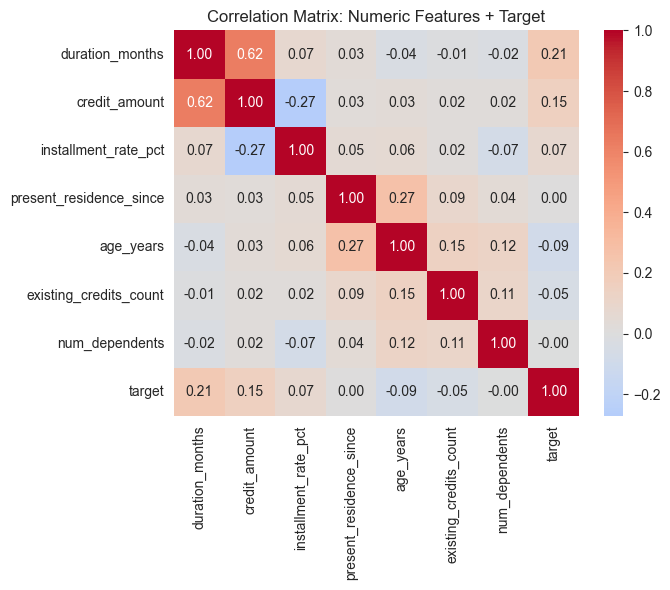

duration_months            0.214927
credit_amount              0.154739
age_years                 -0.091127
installment_rate_pct       0.072404
existing_credits_count    -0.045732
num_dependents            -0.003015
present_residence_since    0.002967
Name: target, dtype: float64

In [9]:
corr = df[NUMERIC_COLS_ + ["target"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix: Numeric Features + Target")
plt.tight_layout()
plt.show()

corr["target"].drop("target").sort_values(key=abs, ascending=False)


All numeric correlations with the target are weak in isolation (|r| < 0.35).
Credit risk here is driven more by categorical factors than by any single
numeric field -- confirmed next.

### 2.7 A categorical predictor that matters: checking account status

In [10]:
rate_tbl = df.groupby("checking_account_status")["target"].agg(["mean", "count"])
rate_tbl = rate_tbl.rename(columns={"mean": "bad_rate"}).sort_values("bad_rate", ascending=False)
rate_tbl.round(3)


,bad_rate,count
checking_account_status,,
< 0 DM,0.493,274
0-200 DM,0.390,269
>= 200 DM,0.222,63
no checking account,0.117,394


**Counterintuitive finding:** applicants with *no checking account at all*
have the **lowest** default rate (11.7%), while those with a negative balance
(`< 0 DM`) have the highest (49.3%). This is a genuine pattern in the data,
not a plotting artifact -- worth flagging rather than assuming "no account"
means "higher risk," which would be the naive guess.

## 3. Preprocessing

Decisions (full write-up in `reports/preprocessing_notes.md`):
1. **Missing values:** none present -- confirmed above, no imputation added.
2. **Categorical encoding:** one-hot (`drop='first'`) for all 13 categorical
   columns. Some are ordinal in principle (checking account status, savings,
   employment length) but bin widths are uneven in real terms, so nominal
   encoding is the safer default; noted as a possible refinement.
3. **Scaling:** `StandardScaler` on the 7 numeric columns -- required for
   Logistic Regression, harmless (no-op on splits) for the tree models.
4. **Split:** stratified 80/20, `random_state=42`, preserving the 70/30
   class ratio in both folds.

In [11]:
X_train, X_test, y_train, y_test = get_train_test_split()
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))

preprocessor = build_preprocessor()
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
print("Encoded feature count:", X_train_enc.shape[1])


Train: (800, 20)  Test: (200, 20)
Train class balance:
 target
0    0.7
1    0.3
Name: proportion, dtype: float64
Test class balance:
 target
0    0.7
1    0.3
Name: proportion, dtype: float64
Encoded feature count: 48


## 4. Baseline Classification Models

Metrics are reported for the **bad-risk (1) class**, since that's the class
that matters to a lender. We also compute a **business cost** using the
dataset's published cost matrix: misclassifying an actual bad risk as good
costs **5x** more than the reverse (a missed defaulter vs. an unnecessarily
declined good customer).

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report, roc_auc_score)

FN_COST, FP_COST = 5, 1

def business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return int(fn * FN_COST + fp * FP_COST)

def evaluate(name, y_true, y_pred, y_proba=None, train_acc=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    row = {
        "model": name,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision_bad": round(precision_score(y_true, y_pred, pos_label=1, zero_division=0), 4),
        "recall_bad": round(recall_score(y_true, y_pred, pos_label=1), 4),
        "f1_bad": round(f1_score(y_true, y_pred, pos_label=1), 4),
        "roc_auc": round(roc_auc_score(y_true, y_proba), 4) if y_proba is not None else np.nan,
        "business_cost": business_cost(y_true, y_pred),
        "confusion_matrix": cm.tolist(),
        "train_accuracy": train_acc,
    }
    return row

results = []

majority_pred = np.zeros_like(y_test)
results.append(evaluate("Majority-class baseline", y_test, majority_pred))

lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_enc, y_train)
results.append(evaluate("Logistic Regression (default)", y_test, lr.predict(X_test_enc), lr.predict_proba(X_test_enc)[:, 1]))

lr_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced").fit(X_train_enc, y_train)
results.append(evaluate("Logistic Regression (balanced)", y_test, lr_bal.predict(X_test_enc), lr_bal.predict_proba(X_test_enc)[:, 1]))

dt = DecisionTreeClassifier(random_state=42).fit(X_train_enc, y_train)
results.append(evaluate("Decision Tree (unpruned)", y_test, dt.predict(X_test_enc), None, round(accuracy_score(y_train, dt.predict(X_train_enc)), 4)))

dt_p = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced").fit(X_train_enc, y_train)
results.append(evaluate("Decision Tree (max_depth=4, balanced)", y_test, dt_p.predict(X_test_enc), dt_p.predict_proba(X_test_enc)[:, 1], round(accuracy_score(y_train, dt_p.predict(X_train_enc)), 4)))

rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train_enc, y_train)
results.append(evaluate("Random Forest (default)", y_test, rf.predict(X_test_enc), rf.predict_proba(X_test_enc)[:, 1]))

rf_bal = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced").fit(X_train_enc, y_train)
results.append(evaluate("Random Forest (balanced)", y_test, rf_bal.predict(X_test_enc), rf_bal.predict_proba(X_test_enc)[:, 1]))

results_df = pd.DataFrame(results)[["model", "accuracy", "precision_bad", "recall_bad", "f1_bad", "roc_auc", "business_cost"]]
results_df


,model,accuracy,precision_bad,recall_bad,f1_bad,roc_auc,business_cost
0,Majority-class baseline,0.700,0.0000,0.0000,0.0000,NaN,300
1,Logistic Regression (default),0.775,0.6531,0.5333,0.5872,0.8058,157
2,Logistic Regression (balanced),0.745,0.5517,0.8000,0.6531,0.8067,99
3,Decision Tree (unpruned),0.620,0.3824,0.4333,0.4062,NaN,212
4,"Decision Tree (max_depth=4, balanced)",0.630,0.4255,0.6667,0.5195,0.6730,154
5,Random Forest (default),0.765,0.6757,0.4167,0.5155,0.7860,187
6,Random Forest (balanced),0.765,0.6857,0.4000,0.5053,0.7934,191


### 4.1 Confusion matrices

In [13]:
for r in results:
    print(f"{r['model']:<42} {r['confusion_matrix']}   (format: [[TN,FP],[FN,TP]])")


Majority-class baseline                    [[140, 0], [60, 0]]   (format: [[TN,FP],[FN,TP]])
Logistic Regression (default)              [[123, 17], [28, 32]]   (format: [[TN,FP],[FN,TP]])
Logistic Regression (balanced)             [[101, 39], [12, 48]]   (format: [[TN,FP],[FN,TP]])
Decision Tree (unpruned)                   [[98, 42], [34, 26]]   (format: [[TN,FP],[FN,TP]])
Decision Tree (max_depth=4, balanced)      [[86, 54], [20, 40]]   (format: [[TN,FP],[FN,TP]])
Random Forest (default)                    [[128, 12], [35, 25]]   (format: [[TN,FP],[FN,TP]])
Random Forest (balanced)                   [[129, 11], [36, 24]]   (format: [[TN,FP],[FN,TP]])


### 4.2 Decision Tree overfitting check

In [14]:
print("Unpruned tree   -- train acc:", results[3]["train_accuracy"], " test acc:", results[3]["accuracy"])
print("Depth=4 tree    -- train acc:", results[4]["train_accuracy"], " test acc:", results[4]["accuracy"])


Unpruned tree   -- train acc: 1.0  test acc: 0.62
Depth=4 tree    -- train acc: 0.735  test acc: 0.63


The unpruned tree memorizes the training set (~100% train accuracy) and
generalizes poorly (test accuracy well below Logistic Regression or Random
Forest) -- it is not a usable model as-is. Limiting depth to 4 and balancing
class weights closes some of that gap and trades accuracy for recall on the
bad-risk class.

### 4.3 Full classification reports for the two most relevant models

In [15]:
print("Logistic Regression (balanced):\n")
print(classification_report(y_test, lr_bal.predict(X_test_enc), target_names=["good(0)", "bad(1)"]))
print("Random Forest (default):\n")
print(classification_report(y_test, rf.predict(X_test_enc), target_names=["good(0)", "bad(1)"]))


Logistic Regression (balanced):

              precision    recall  f1-score   support

     good(0)       0.89      0.72      0.80       140
      bad(1)       0.55      0.80      0.65        60

    accuracy                           0.74       200
   macro avg       0.72      0.76      0.73       200
weighted avg       0.79      0.74      0.75       200

Random Forest (default):

              precision    recall  f1-score   support

     good(0)       0.79      0.91      0.84       140
      bad(1)       0.68      0.42      0.52        60

    accuracy                           0.77       200
   macro avg       0.73      0.67      0.68       200
weighted avg       0.75      0.77      0.75       200



### 4.4 Honest comparison

- The **majority-class baseline** already gets 70% accuracy for free -- every
  model above must be read relative to that floor.
- **Random Forest (default)** has the highest accuracy and best precision on
  the bad-risk class, but its recall on bad risk is the weakest of the
  non-trivial models -- it misses more actual defaulters than Logistic
  Regression does.
- **Logistic Regression (balanced)** has lower raw accuracy but the best
  recall on bad risk and, critically, the **lowest business cost** under the
  dataset's stated 5:1 cost asymmetry -- because it misses fewer of the
  expensive false negatives (missed defaulters).
- This is the real trade-off, not a flaw in the analysis: **the "best" model
  depends on what a lender is optimizing for.** If you only report accuracy,
  Random Forest looks best. If you weight by the bank's own stated cost
  matrix, Logistic Regression (balanced) wins.

## 5. Borrower Segmentation with K-Means (Unsupervised)

A separate analysis from the classification task above. The target column is
**never used to fit the clusters** -- it's only joined back afterward to
describe what the resulting segments look like.

Only the 7 numeric attributes are used as clustering features (categorical
one-hot columns were excluded -- 41 sparse dummy columns would dominate
Euclidean distance and wash out the numeric signal).

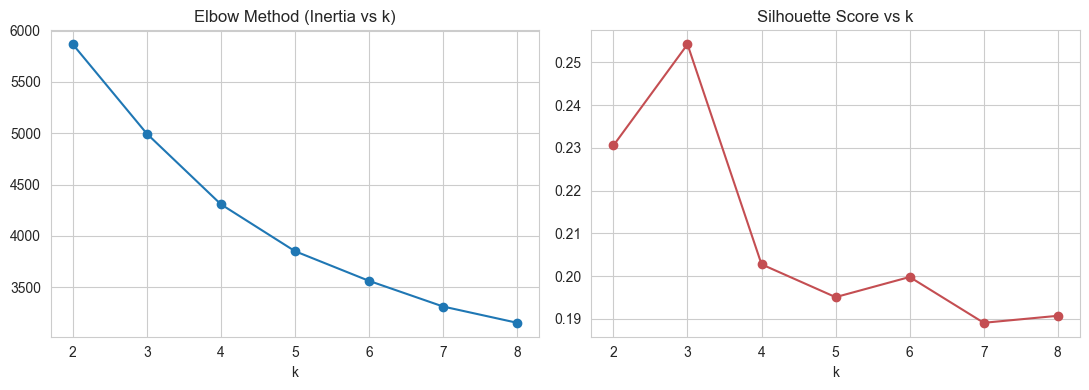

Best k by silhouette: 3  silhouette = 0.2542


In [16]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

X_cluster = df[NUMERIC_COLS_].copy()
X_cluster_scaled = StandardScaler().fit_transform(X_cluster)

ks = list(range(2, 9))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Elbow Method (Inertia vs k)")
axes[0].set_xlabel("k")
axes[1].plot(ks, silhouettes, marker="o", color="#C44E52")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

best_k = ks[int(np.argmax(silhouettes))]
print("Best k by silhouette:", best_k, " silhouette =", round(max(silhouettes), 4))


A silhouette score well under 0.5 means the clusters are real but
overlapping, not cleanly separated -- expected for demographic/financial
survey data with no natural gaps between groups. Reported honestly rather
than picking a k that looks more impressive.

In [17]:
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster"] = km_final.fit_predict(X_cluster_scaled)

print("Cluster sizes:")
print(df["cluster"].value_counts().sort_index())

print("\nCluster profiles (mean of numeric features):")
display(df.groupby("cluster")[NUMERIC_COLS_].mean().round(1))

print("\nCluster bad-risk rate (target joined back for description only):")
print(df.groupby("cluster")["target"].mean().round(3))

print("\nMost common loan purpose per cluster:")
print(df.groupby("cluster")["purpose"].agg(lambda s: s.value_counts().idxmax()))


Cluster sizes:
cluster
0    173
1    686
2    141
Name: count, dtype: int64

Cluster profiles (mean of numeric features):


,duration_months,credit_amount,installment_rate_pct,present_residence_since,age_years,existing_credits_count,num_dependents
cluster,,,,,,,
0,38.9,7936.9,2.6,2.8,35.5,1.4,1.1
1,17.0,2187.8,3.1,2.8,34.9,1.4,1.0
2,18.1,2818.0,2.8,2.9,38.8,1.6,2.0



Cluster bad-risk rate (target joined back for description only):
cluster
0    0.474
1    0.257
2    0.298
Name: target, dtype: float64

Most common loan purpose per cluster:
cluster
0          car (used)
1    radio/television
2           car (new)
Name: purpose, dtype: object


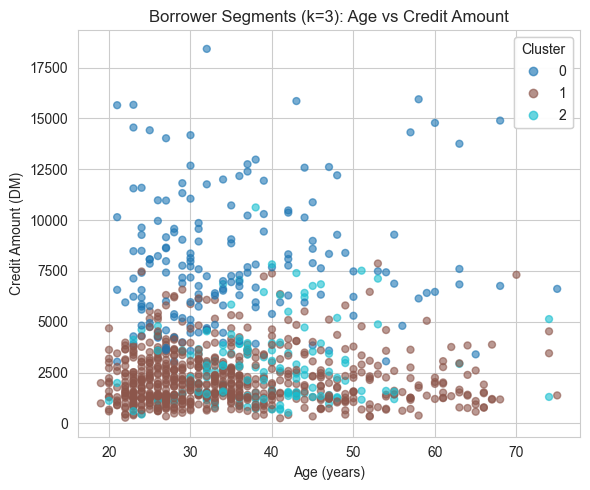

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
scatter = ax.scatter(df["age_years"], df["credit_amount"], c=df["cluster"], cmap="tab10", alpha=0.6, s=25)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Credit Amount (DM)")
ax.set_title(f"Borrower Segments (k={best_k}): Age vs Credit Amount")
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster", loc="upper right")
ax.add_artist(legend1)
plt.tight_layout()
plt.show()


**Finding:** the cluster with large, long-duration loans (avg. credit
amount ~ 4x the smallest cluster) has a visibly higher default rate than the
other two segments -- a pattern that lines up with intuition (bigger, longer
loans carry more risk) and matches the standalone `purpose` and `duration`
signal seen in the EDA above.

## 6. SQL Queries

The cleaned dataset is also loaded into a local SQLite database
(`data/german_credit.db`) so exploratory questions can be answered in SQL
directly, not just pandas.

In [19]:
import sqlite3

conn = sqlite3.connect("../data/german_credit.db")
df_for_sql = load_labeled()
df_for_sql.to_sql("credit", conn, if_exists="replace", index=False)


1000

In [20]:
q1 = '''
SELECT checking_account_status, COUNT(*) AS n_customers, SUM(target) AS n_bad,
       ROUND(AVG(target * 1.0), 3) AS bad_rate
FROM credit
GROUP BY checking_account_status
ORDER BY bad_rate DESC;
'''
pd.read_sql_query(q1, conn)


,checking_account_status,n_customers,n_bad,bad_rate
0,< 0 DM,274,135,0.493
1,0-200 DM,269,105,0.390
2,>= 200 DM,63,14,0.222
3,no checking account,394,46,0.117


In [21]:
q2 = '''
SELECT purpose, COUNT(*) AS n_customers,
       ROUND(AVG(credit_amount), 0) AS avg_credit_amount,
       ROUND(AVG(duration_months), 1) AS avg_duration_months,
       ROUND(AVG(target * 1.0), 3) AS bad_rate
FROM credit
GROUP BY purpose
HAVING COUNT(*) >= 20
ORDER BY bad_rate DESC;
'''
pd.read_sql_query(q2, conn)


,purpose,n_customers,avg_credit_amount,avg_duration_months,bad_rate
0,education,50,3180.0,21.1,0.440
1,car (new),234,3063.0,18.5,0.380
2,repairs,22,2728.0,19.1,0.364
3,business,97,4158.0,26.9,0.351
4,furniture/equipment,181,3067.0,19.3,0.320
5,radio/television,280,2488.0,20.0,0.221
6,car (used),103,5370.0,26.1,0.165


In [22]:
q3 = '''
SELECT
  CASE
    WHEN age_years < 25 THEN 'under 25'
    WHEN age_years < 35 THEN '25-34'
    WHEN age_years < 45 THEN '35-44'
    WHEN age_years < 55 THEN '45-54'
    ELSE '55+'
  END AS age_bucket,
  COUNT(*) AS n_customers,
  ROUND(AVG(target * 1.0), 3) AS bad_rate,
  ROUND(AVG(credit_amount), 0) AS avg_credit_amount
FROM credit
GROUP BY age_bucket
ORDER BY age_bucket;
'''
pd.read_sql_query(q3, conn)


,age_bucket,n_customers,bad_rate,avg_credit_amount
0,25-34,399,0.328,3293.0
1,35-44,251,0.231,3425.0
2,45-54,122,0.230,3175.0
3,55+,79,0.278,3411.0
4,under 25,149,0.409,2959.0


In [23]:
conn.close()


## 7. Summary & Honest Caveats

**What worked:** Logistic Regression and Random Forest both clear the 70%
majority-class floor by a real margin, and the direction of every finding
(checking account status, loan purpose, age, loan size) is consistent across
the pandas EDA, the SQL queries, and the model's own behavior.

**What didn't:** the unpruned Decision Tree overfits badly and isn't usable
as a standalone model. No model here achieves strong recall *and* strong
precision on the bad-risk class simultaneously -- this is a real 300-row
minority class in a 1000-row dataset, and no amount of tuning invents data
that isn't there.

**Caveats a hiring manager should know:**
- This is StatLog's pre-cleaned version of the German Credit data (no missing
  values, no duplicates) -- a real bank feed would need real data-cleaning
  work this project didn't have to do.
- The dataset is small (1000 rows) and from 1994 Germany -- absolute credit
  amounts (DM) and demographic patterns will not transfer directly to a
  modern market.
- K-Means silhouette scores (~0.25) indicate soft, overlapping segments, not
  cleanly separated customer types -- described as such, not oversold.
- "Best model" depends on the metric: Random Forest wins on accuracy/F1,
  Logistic Regression (balanced) wins on the dataset's own stated business
  cost. Both are reported; neither is hidden.
